## 회귀 모델 (알고리즘)
- 회귀 : 연속적인 수치(숫자)를 예측하는 모델
- 분류 vs 회귀
  - 분류 : 범주(up/down)를 예측하며, 예측이 맞았는지/틀렸는지가 명확(혼동행렬, 정확도)
  - 회귀 : 연속적인 수치를 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from _ml import build_dataset, time_split, FEATURES, SEED
from _style import setup

setup()
pd.set_option("display.width", 130)      

df = build_dataset()
train, test, cutoff = time_split(df)

tr = train.sample(15000, random_state=SEED)
te = test.sample(4000, random_state=SEED)

x_train, X_test = tr[FEATURES], te[FEATURES]

#정답(y)을 두 종류 준비 -> 분류/회귀
y_train_cls, y_test_cls = tr["target_up"], te["target_up"]
y_train_reg, y_test_reg = tr["target_ret"], te["target_ret"]

print(f" * 학습 {len(tr):,}행 ({tr['date'].min().date()} ~ {tr['date'].max().date()})")
print(f" * 테스트 {len(te):,}행 ({te['date'].min().date()} ~ {te['date'].max().date()})")
print(f" * 피처{len(FEATURES):,}개")
print()
print(f" - 분류용 정답(target_up) : {y_train_cls.unique()} (범주)")
print(f" - 회귀용 정답(target_ret) : {y_train_reg.min():.4f} ~ {y_train_reg.max():.4f} (수치)")



 * 학습 15,000행 (2023-10-24 ~ 2026-01-16)
 * 테스트 4,000행 (2026-01-19 ~ 2026-09-07)
 * 피처7개

 - 분류용 정답(target_up) : [0 1] (범주)
 - 회귀용 정답(target_ret) : -0.2260 ~ 0.2313 (수치)


- 분류 : y = target_up (0/1) --> RandomForestClassifier
- 회귀 : y = target_ret (수익률) --> RandomForestRefressor

** 이름은 동일한 알고리즘이지만, 평가 방법이 안전히 달라짐 **
- RandomForestClassifier => accuracy_score(정확도), f1_score(f1 점수)
- RandomForestRegressor => mean_absolute_error(MAE), mean_squared_error(MSE),r2_score(R^2) 

In [4]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor 

from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, mean_squared_error, r2_score)

clf = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=SEED, n_jobs=-1)
reg = RandomForestRegressor(n_estimators=100, max_depth=6, random_state=SEED, n_jobs=-1)

# 학습 --> fit(X.y)
# 분류 모델 학습
clf.fit(x_train, y_train_cls)

# 회귀 모델 학습
reg.fit(x_train, y_train_reg)

# 예측 --> pred = predict(X_test)
# 분류 모델 예측 (pred_cls)
pred_clf = clf.predict(X_test)

pred_reg = reg.predict(X_test)

print(f"{'':<14}{'분류':<32}{'회귀'}")
print('-' * 70)
print(f"{'정답예시':<13}{y_test_cls.iloc[0]:<32}{y_test_reg.iloc[0]:.4f}")
print(f"{'예측예시':<13}{pred_clf[0]:<32}{pred_reg[0]:.4f}") 
print()
print(f"분류평가 : 정확도 {accuracy_score(y_test_cls, pred_clf):.4f}",
      f"    F1 {f1_score(y_test_cls, pred_clf):.4f}")

print(f"회귀 평가 : RMSE { np.sqrt(mean_squared_error(y_test_reg, pred_reg)):.6f}",
      f"    R^2 {r2_score(y_test_reg, pred_reg):.4f}")





              분류                              회귀
----------------------------------------------------------------------
정답예시         0                               -0.0068
예측예시         1                               -0.0000

분류평가 : 정확도 0.4933     F1 0.4269
회귀 평가 : RMSE 0.027389     R^2 -0.0068


In [ ]:
# 회귀 예측을 0 기준으로 나누어서 분류를 해본다면 ?

pred_cls = (pred_reg > 0).astype(int)

print(f"회귀 모델 예측을 0 기준으로 나눈 정확도 :"
      f" {accuracy_score(y_test_cls, pred_cls):.4f}")
print(f"분류 모델로 학습한 정확도: "
      f" {accuracy_score(y_test_cls, pred_clf):.4f}")


---
## LinearRegression (선형 회귀)
가장 단순한 선형 회귀 모델. 직선으로 관계를 표현
'예측값 = w1*ret_1d + w2*ret_5d + ... + b'

- 학습 : **오차의 제곱합(MSE)이 가장 작아지는 가중치(w)와 절편(b)를 찾는 것
    - w = 가중치(계수):다른피처가 그대로일 때, 해당 피처가 1증가하면 예측값이 얼마나 변하는지
    - b = 절편(방향)

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

def make(model):
    return Pipeline([("sc", StandardScaler()), ("m", model)])

lin = make(LinearRegression())

lin.fit(x_train, y_train_reg)

coef = pd.Series(lin.named_steps["m"].coef_, index=FEATURES).sort_values()

intercept = lin.named_steps["m"].intercept_

print(f"* 절편 (b) : {intercept:.6f}")
print()
print(f"* 가중치 (w) :")
print(coef.round(6).to_string)


* 절편 (b) : -0.000063

* 가중치 (w) :
<bound method Series.to_string of vol20          -0.000567
ma20_ratio     -0.000507
volume_ratio   -0.000161
range_pct       0.000055
ma5_ratio       0.000117
ret_5d          0.000544
ret_1d          0.000756
dtype: float64>


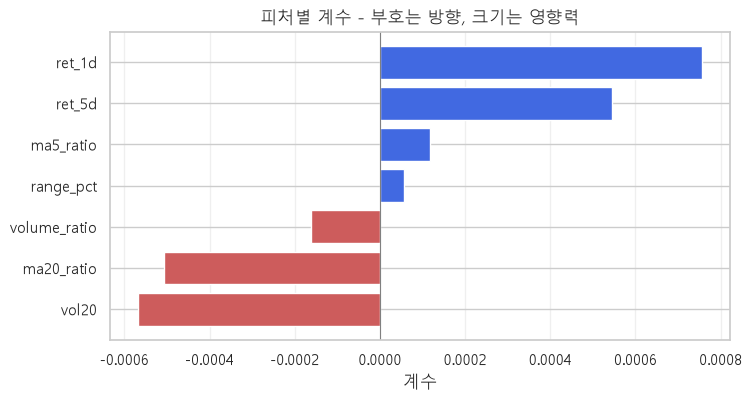

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))  

colors = ["indianred" if v < 0 else "royalblue" for v in coef.values]

ax.barh(coef.index, coef.values, color=colors)

ax.axvline(0, color="gray", lw=0.8)
ax.set_xlabel("계수")
ax.set_title("피처별 계수 - 부호는 방향, 크기는 영향력")
ax.grid(alpha=0.3, axis="x")

plt.show()

**계수(가중치)는 해석을 도와주는 지표**
계수의 부호는 방향 (+ 올리는 쪽/- 내리는 쪽)을, 절댓값은 영향력의 크기를 알려줌 
다만, 피처의 스케일(단위)이 다르면 계수 크기를 직접 비교할 수 없으므로 **스케일링을 먼저** 진행해야 함

또한 피처끼리 서로 비슷하다면(다중 공선성) 계수가 불안정해져서 해석이 틀어질 수 있음.
(우리 데이터의 계수는 모두 0에 가까운 아주 작은 값이므로, 선형 관계가 거의 없다고 볼 수 있음)

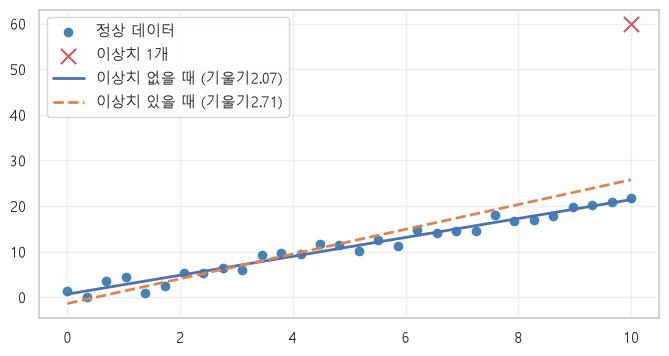

In [18]:
#이상치 하나 넣어서 직선의 변화를 확인해보가
rng = np.random.default_rng(SEED)       # 난수 생성기

x_demo = np.linspace(0, 10, 30)         # 0 ~ 10 구간을 균등하게 나눈 30개의 숫자
#y = 2x + 1 에 노이즈 추가 (평균 0, 표준편차 1.5인 오차 30개)
y_demo = 2 * x_demo + 1 + rng.normal(0, 1.5, 30)

#이상치 1개 추가 : x=10 인데, y=60 (원래대로라면 21 근처 값이어야 함)
x_bad = np.append(x_demo, 10)
y_bad = np.append(y_demo, 60)

fig, ax = plt.subplots(figsize=(8,4))

ax.scatter(x_demo, y_demo, label = "정상 데이터", color="steelblue")
ax.scatter([10], [60], s=120, label = "이상치 1개", color="indianred", marker="x", zorder=5)

datas = [
    (x_demo, y_demo, "-", "이상치 없을 때"),
    (x_bad, y_bad, "--", "이상치 있을 때")
]

for xs, ys, d, name in datas:
    m = LinearRegression().fit(xs.reshape(-1,1),ys)

    xx = np.linspace(0, 10, 10)
    ax.plot(xx, m.predict(xx.reshape(-1, 1)), d, lw=2, label=f"{name} (기울기{m.coef_[0]:.2f})")

    ax.legend()
    ax.grid(alpha=0.3)
    ax.set_title

    plt.show